# Part 4 · What happened to tracked players?
We use the casino’s loyalty-card records to measure wagers, machine payouts and net outcomes over January–June 2025. We first count each active player once, then examine how much of the total wagering and losses came from the largest contributors. The results describe recorded carded play at this fictional property.

**Running in Colab.** Run the cells from top to bottom. The setup downloads the competition repository if needed. To explore another period, change the two months in 4A and rerun that cell and everything below it. The written numerical examples refer to the full six-month period.

## Load the player-month data
The input is the prepared player table. One record summarizes one cardholder in one month. A player appearing in three months contributes three records. The preview lets you check the direction of the dollar amounts: in the first row, $134.50 paid back minus $146.75 wagered gives a player net of −$12.25. Wagers can include winnings that were bet again.

In [1]:
from pathlib import Path
import pandas as pd

import subprocess

repo = Path.cwd() / "dashboard-royale"
if not repo.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/tamu-datathon-org/dashboard-royale.git", str(repo)],
        check=True,
    )
data_dir = repo / "data" / "1_prepared_views"
guests = pd.read_csv(data_dir / "player_period.csv.gz")

print(f"Player-month rows: {len(guests):,}")
print(f"Unique cardholders: {guests['player_id'].nunique():,}")

display(guests[[
    "player_id",
    "period_month",
    "tracked_coin_in_usd",
    "tracked_payout_usd",
    "tracked_net_usd",
]].head())

Player-month rows: 148,893
Unique cardholders: 113,890


,player_id,period_month,tracked_coin_in_usd,tracked_payout_usd,tracked_net_usd
0,P000044f627282c13,2025-04,146.75,134.50,-12.25
1,P00005528b66728e6,2025-01,191.00,132.50,-58.50
2,P00007a93f32777c5,2025-06,1204.05,692.15,-511.90
3,P0000b3c582d574a5,2025-04,173.00,390.75,217.75
4,P0000c4c5499f6ee9,2025-02,414.40,390.20,-24.20


## 4A · Build one row per active player
Filter by month first so the outcome belongs to the period shown on the dashboard. Then sum each person’s monthly wagers, payouts and net in integer cents. For example, a $200 win in January and a $250 loss in February combine to a $50 loss. The assertion checks the accounting identity separately for every player.

Of 113,890 cardholders in the full-period table, 17,331 had zero tracked wagers. Removing them leaves 96,559 who actually played. Someone who wagered and received exactly the same amount back remains in the analysis as a break-even player.

In [2]:
# Select the months to analyze.
start_month = "2025-01"
end_month = "2025-06"

selected = guests.loc[
    guests["period_month"].between(start_month, end_month)
].copy()

# Use whole cents so a break-even result is exactly zero.
selected["wager_cents"] = (selected["tracked_coin_in_usd"] * 100).round().astype("int64")
selected["payout_cents"] = (selected["tracked_payout_usd"] * 100).round().astype("int64")
selected["net_cents"] = (selected["tracked_net_usd"] * 100).round().astype("int64")

# Combine each player's monthly records into one row.
players = selected.groupby("player_id")[
    ["wager_cents", "payout_cents", "net_cents"]
].sum()

# Verify the recorded net for every player.
assert (players["payout_cents"] - players["wager_cents"] == players["net_cents"]).all()

# Keep players who actually placed a tracked wager during these months.
print(f"Cardholders with zero wagers: {(players['wager_cents'] == 0).sum():,}")
active_players = players.loc[players["wager_cents"] > 0].copy()
print(f"Active tracked players: {len(active_players):,}")

Cardholders with zero wagers: 17,331
Active tracked players: 96,559


## 4B · Count outcomes and reconcile the dollars
Each player contributes once to the ahead, even or behind count. Summing the three counts checks that every active player was classified. Dividing each count by the number of active players gives the share in that category.

The combined net measures the dollar outcome across everyone. The median sorts the individual outcomes and takes the middle one. For January–June, 15,504 players finished ahead, 63 broke even and 80,992 finished behind. Combined player net was −$15,585,460.60, while the middle player finished $96 behind.

In [3]:
# Each value is one player's net outcome over the selected months.
net = active_players["net_cents"]

# Count players by outcome and check that everyone is counted once.
# In pandas, summing a True/False comparison counts the True entries.
outcomes = pd.Series({
    "Finished ahead": (net > 0).sum(),
    "Broke even":     (net == 0).sum(),
    "Finished behind": (net < 0).sum(),
}, name="Players")

assert outcomes.sum() == len(active_players)

summary = outcomes.to_frame()
summary["Share of active players (%)"] = 100 * outcomes / len(active_players)
display(summary.round(2))

# Keep calculations in cents and convert to dollars for display.
wagered = active_players["wager_cents"].sum()
paid_back = active_players["payout_cents"].sum()
assert paid_back - wagered == net.sum()

print(f"Total wagered ($):       {wagered / 100:,.2f}")
print(f"Total paid back ($):     {paid_back / 100:,.2f}")
print(f"Combined player net ($): {net.sum() / 100:,.2f}")
print(f"Median player net ($):   {net.median() / 100:,.2f}")

,Players,Share of active players (%)
Finished ahead,15504,16.06
Broke even,63,0.07
Finished behind,80992,83.88


Total wagered ($):       163,804,869.65
Total paid back ($):     148,219,409.05
Combined player net ($): -15,585,460.60
Median player net ($):   -96.00


## 4C · Measure concentration
Rank all active players by wager volume. The first percentage divides wagers by the highest-wagering tenth by all tracked wagers. For the second percentage, keep only players with negative net and turn losses into positive magnitudes. This makes a $500 loss rank above a $50 loss. Rank those players by loss and divide the largest tenth’s losses by all losses in that group.

The populations differ. The 9,656 highest-wagering players account for 63.97% of wagers. Among players who finished behind, the 8,100 with the largest losses account for 52.84% of losses. Winnings from players who finished ahead already offset losses in the combined net from 4B, so that net would give the wrong denominator here.

In [4]:
import math

# Each row already represents one active player over the selected months.
wagers = active_players["wager_cents"]
net = active_players["net_cents"]

# Express losses as positive amounts so the largest loss ranks first.
losses = -net[net < 0]

# Round group sizes up to a whole player.
top_wager_count = math.ceil(len(wagers) * 0.10)
top_loss_count = math.ceil(len(losses) * 0.10)

# Add the top group's dollars and divide by the corresponding total.
wager_share = 100 * wagers.nlargest(top_wager_count).sum() / wagers.sum()
loss_share = 100 * losses.nlargest(top_loss_count).sum() / losses.sum()

print(f"Top {top_wager_count:,} players by wager volume: {wager_share:.2f}% of wagers")
print(f"Top {top_loss_count:,} net losers by loss size: {loss_share:.2f}% of losses")

Top 9,656 players by wager volume: 63.97% of wagers
Top 8,100 net losers by loss size: 52.84% of losses


## 4D · Compare wagering volume and realized loss rate
Selecting the largest-loss tenth guarantees they lost more dollars. What remains interesting is how their wager volume and loss per dollar compare. Use the player IDs from 4C to keep the groups consistent. Average wagers and losses per player account for the different group sizes. For the realized loss rate, divide each group’s total loss by its total wagers and multiply by 100. This weights each wager dollar equally.

A useful cross-check is **average wagers per player × loss per $100 ÷ 100 ≈ average loss per player**. Small differences arise if you use rounded numbers from the table.

In [5]:
# Start with the players who finished behind during the selected period.
comparison = active_players.loc[losses.index].copy()

# Use the same top 10% group you calculated in Part 4C.
# The player IDs are the index of the Series returned by nlargest().
top_loss_ids = losses.nlargest(top_loss_count).index
comparison["group"] = "Other net losers"
comparison.loc[top_loss_ids, "group"] = "Largest-loss 10%"

# Convert cents to dollars and express each loss as a positive amount.
comparison["wager_usd"] = comparison["wager_cents"] / 100
comparison["loss_usd"] = -comparison["net_cents"] / 100

# Summarize the two groups.
groups = comparison.groupby("group")
results = groups.agg(
    players=("loss_usd", "size"),
    avg_wagered_usd=("wager_usd", "mean"),
    avg_loss_usd=("loss_usd", "mean"),
)

# For every $100 wagered by the group, how many dollars did it lose?
results["loss_per_100_wagered"] = (
    100 * groups["loss_usd"].sum() / groups["wager_usd"].sum()
)

assert results["players"].sum() == len(losses)
display(results.round(2))

,players,avg_wagered_usd,avg_loss_usd,loss_per_100_wagered
group,,,,
Largest-loss 10%,8100,10817.63,1365.98,12.63
Other net losers,72892,812.36,135.47,16.68


### Figure 1 · Why the largest-loss group lost more in dollars
The left panel shows average wagers per person: $10,817.63 versus $812.36. The right panel shows realized loss per $100 wagered: $12.63 versus $16.68. Read each panel using its own scale. The reversal matters: the largest-loss group wagered about 13.3 times as much per player, even though its realized loss per dollar was lower. Historical groups selected by their outcomes cannot establish future player risk or differences in game odds.

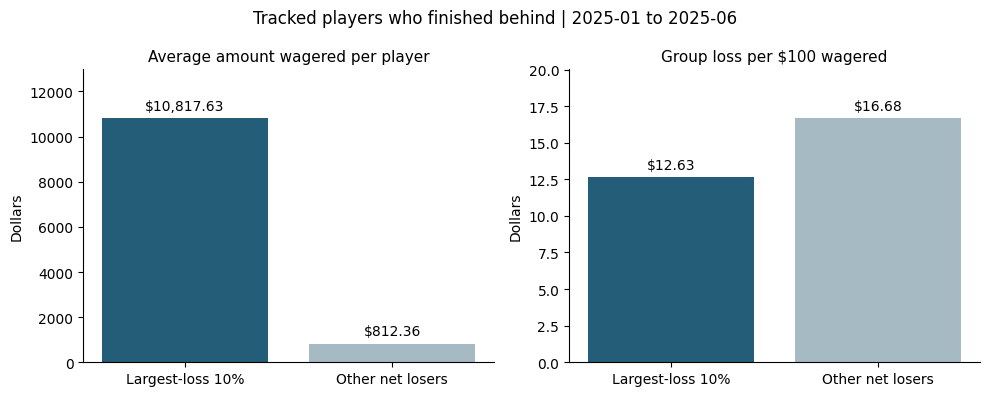

In [6]:
import matplotlib.pyplot as plt

plot_groups = results.loc[["Largest-loss 10%", "Other net losers"]]
labels = ["Largest-loss 10%", "Other net losers"]
colors = ["#245D78", "#A6BAC4"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, column, title in [
    (axes[0], "avg_wagered_usd", "Average amount wagered per player"),
    (axes[1], "loss_per_100_wagered", "Group loss per $100 wagered"),
]:
    values = plot_groups[column]
    bars = ax.bar(labels, values, color=colors)
    ax.bar_label(bars, labels=[f"${v:,.2f}" for v in values], padding=4)
    ax.set_ylim(0, values.max() * 1.20)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Dollars")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"Tracked players who finished behind | {start_month} to {end_month}")
fig.tight_layout()
plt.show()

### Figure 2 · Who accounted for the wagers and losses?
The bars show two separately ranked groups and two different dollar totals. Read each label with its bar. The 52.84% applies to losses among players who finished behind. Adding the two bar percentages has no interpretable meaning.

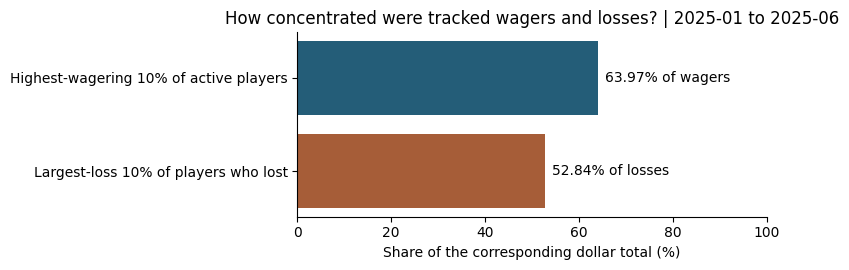

In [7]:
fig, ax = plt.subplots(figsize=(8, 2.8))

bars = ax.barh(
    ["Highest-wagering 10% of active players",
     "Largest-loss 10% of players who lost"],
    [wager_share, loss_share],
    color=["#245D78", "#A65D38"],
)

ax.bar_label(
    bars,
    labels=[f"{wager_share:.2f}% of wagers", f"{loss_share:.2f}% of losses"],
    padding=5,
)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the corresponding dollar total (%)")
ax.set_title(f"How concentrated were tracked wagers and losses? | {start_month} to {end_month}")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

4A. Calculate each player’s result
The data contains one row per player per month. We added up each player’s wagers and payouts from January through June 2025. We then calculated their net result by subtracting the amount they wagered from the amount they received back.

Combining the months first matters because a player can win in one month and lose in another. For example, someone who won $200 in January and lost $250 in February finished those two months $50 behind. We counted that person once.

We included the 96,559 players who placed at least one tracked wager. We excluded 17,331 cardholders who had no recorded wagers. This let us distinguish people who played and broke even from people who had no tracked play.
4B. Summarize wins and losses
A player finished ahead if their payouts exceeded their wagers, behind if their wagers exceeded their payouts, and even if the two amounts matched. Across the six months, 15,504 players finished ahead, 80,992 finished behind, and 63 broke even.

Together, these players wagered $163.80 million and received $148.22 million back, for a combined net loss of $15.59 million. To describe the experience of a typical player, we also calculated the median. When we ranked all active players from the largest loss to the largest gain, the player in the middle finished $96 behind.
4C. Measure how concentrated wagers and losses were
We ranked all active players by how much they wagered. We added up the wagers of the highest-wagering 10% and divided that amount by total tracked wagers. Those 9,656 players accounted for 63.97% of all tracked wagers.

We repeated the calculation for losses using only the players who finished behind. We ranked them by how much they lost, then divided the losses of the top 10% by the total losses of everyone in that group. The 8,100 players with the largest losses accounted for 52.84% of the dollars lost by players who finished behind. This calculation excludes winners’ gains because the question asks how losses were distributed among those who lost money.
4D. Explain why the largest losses were concentrated
We compared the 8,100 players with the largest losses against the other players who finished behind. For each group, we calculated the average amount wagered per player and how much the group lost per $100 wagered. To find the second measure, we divided the group’s total loss by its total wagers and multiplied by 100.

The largest-loss group wagered an average of $10,817.63 per player and lost $12.63 per $100 wagered. The remaining players who finished behind wagered an average of $812.36 per player and lost $16.68 per $100 wagered.

The largest-loss group therefore lost a smaller share of each dollar it wagered, but it wagered 13.3 times as much per person. That difference in wagering volume explains how its average loss reached $1,365.98 per player, compared with $135.47 for the other group. These findings describe tracked play during the six-month study period.